###Connect Project & Load Dataset

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import sys

sys.path.insert(
    0, "/content/drive/MyDrive/ArteryAI/src"
)

from config import *

Mounted at /content/drive


In [ ]:
!pip -q install datasets

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from datasets import load_from_disk

artery_data = load_from_disk(
    str(RAW_DIR / "syntax")
)

stenosis_data = load_from_disk(
    str(RAW_DIR / "stenosis")
)

print("Datasets loaded successfully!")

Datasets loaded successfully!


###Create Reusable Preprocessing Module

In [ ]:
%%writefile /content/drive/MyDrive/ArteryAI/src/preprocessing.py

import cv2
import numpy as np

def validate_image(image):

    image = np.asarray(image)

    if image.size == 0:
        raise ValueError("Empty image")

    if image.ndim not in [2, 3]:
        raise ValueError("Invalid image dimensions")

    return image


def to_grayscale(image):

    image = validate_image(image)

    if image.ndim == 3:

        if image.shape[-1] == 4:
            image = cv2.cvtColor(
                image, cv2.COLOR_RGBA2GRAY
            )
        else:
            image = cv2.cvtColor(
                image, cv2.COLOR_RGB2GRAY
            )

    return image


def normalize_intensity(image):

    image = cv2.normalize(
        image,
        None,
        0,
        255,
        cv2.NORM_MINMAX
    )

    return image.astype(np.uint8)


def reduce_noise(image):

    return cv2.GaussianBlur(
        image, (3, 3), 0
    )


def enhance_contrast(image):

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    return clahe.apply(image)


def extract_roi(image):

    # Preserve full field of view initially.
    # Vessel-specific ROI will be extracted
    # after segmentation.

    return image


def preprocess_image(image, size=256):

    image = to_grayscale(image)

    image = normalize_intensity(image)

    image = reduce_noise(image)

    image = enhance_contrast(image)

    image = extract_roi(image)

    image = cv2.resize(
        image,
        (size, size),
        interpolation=cv2.INTER_AREA
    )

    image = image.astype(np.float32) / 255.0

    return image


def preprocess_mask(mask, size=256, binary=True):

    mask = np.asarray(mask)

    if mask.ndim != 2:
        raise ValueError(
            "Expected single-channel label mask"
        )

    mask = cv2.resize(
        mask,
        (size, size),
        interpolation=cv2.INTER_NEAREST
    )

    if binary:
        mask = (mask > 0).astype(np.float32)
    else:
        mask = mask.astype(np.int64)

    return mask


def augment_pair(image, mask):

    if np.random.rand() < 0.5:

        image = np.flip(image, axis=1)
        mask = np.flip(mask, axis=1)

    if np.random.rand() < 0.5:

        angle = np.random.uniform(-10, 10)

        h, w = image.shape[:2]

        matrix = cv2.getRotationMatrix2D(
            (w / 2, h / 2),
            angle,
            1.0
        )

        image = cv2.warpAffine(
            image,
            matrix,
            (w, h),
            flags=cv2.INTER_LINEAR
        )

        mask = cv2.warpAffine(
            mask.astype(np.float32),
            matrix,
            (w, h),
            flags=cv2.INTER_NEAREST
        ).astype(mask.dtype)

    if np.random.rand() < 0.5:

        factor = np.random.uniform(0.9, 1.1)

        image = np.clip(
            image * factor, 0, 1
        )

    return (
        np.ascontiguousarray(image),
        np.ascontiguousarray(mask)
    )

Overwriting /content/drive/MyDrive/ArteryAI/src/preprocessing.py


###Visualize Each Preprocessing Stage

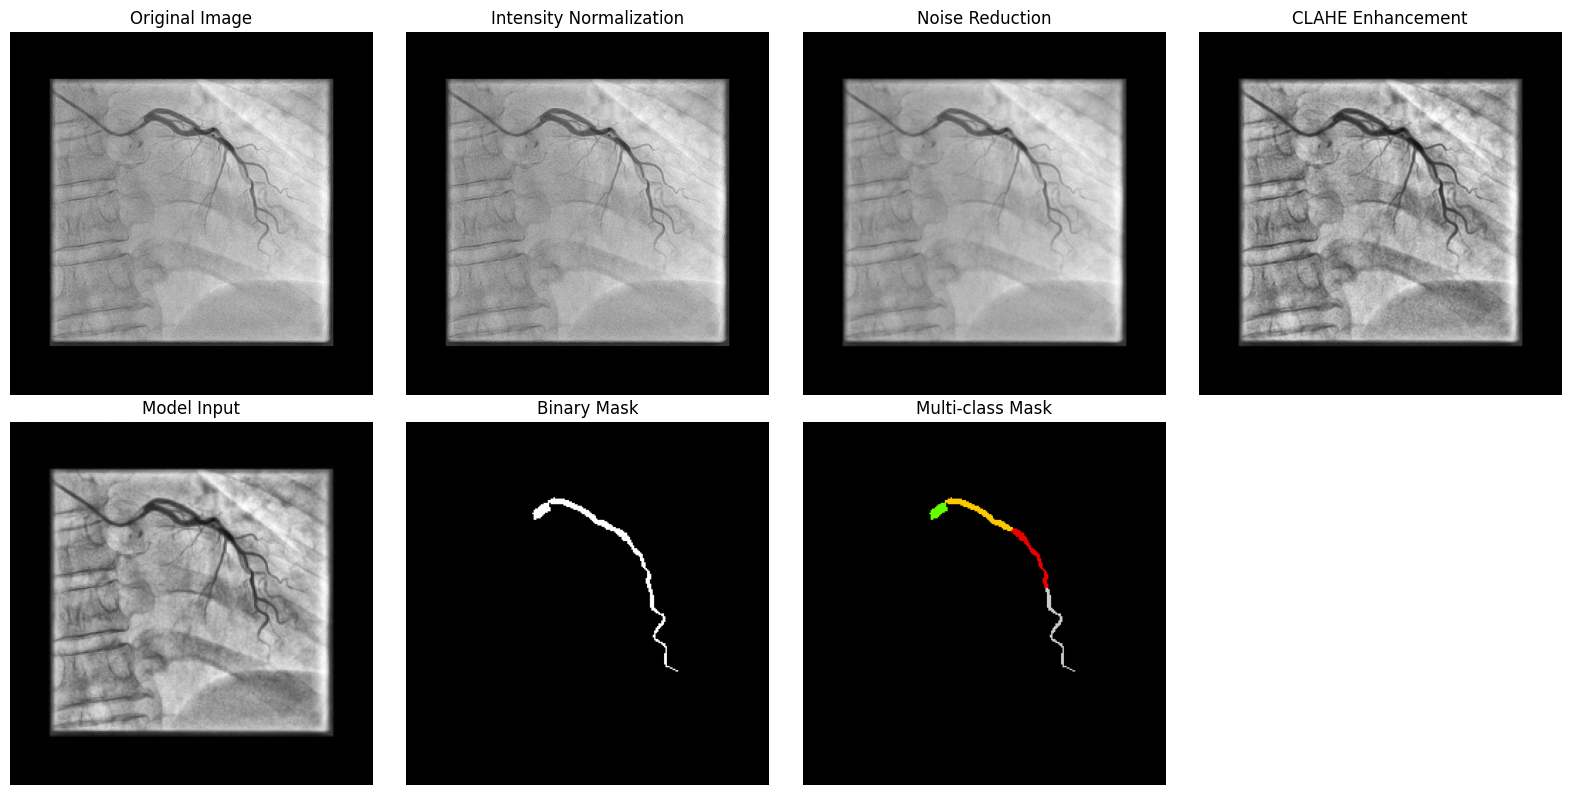

In [ ]:
from preprocessing import *

sample = artery_data["train"][0]

original = np.array(
    sample["image"].convert("L")
)

normalized = normalize_intensity(original)

denoised = reduce_noise(normalized)

enhanced = enhance_contrast(denoised)

processed = preprocess_image(
    original, IMAGE_SIZE
)

binary_mask = preprocess_mask(
    sample["mask"],
    IMAGE_SIZE,
    binary=True
)

multiclass_mask = preprocess_mask(
    sample["mask"],
    IMAGE_SIZE,
    binary=False
)

stages = [
    ("Original Image", original),
    ("Intensity Normalization", normalized),
    ("Noise Reduction", denoised),
    ("CLAHE Enhancement", enhanced),
    ("Model Input", processed),
    ("Binary Mask", binary_mask),
    ("Multi-class Mask", multiclass_mask)
]

fig, axes = plt.subplots(
    2, 4, figsize=(16, 8)
)

for ax in axes.flat:
    ax.axis("off")

for ax, (title, img) in zip(
    axes.flat, stages
):

    ax.imshow(
        img,
        cmap="nipy_spectral"
        if title == "Multi-class Mask"
        else "gray"
    )

    ax.set_title(title)

plt.tight_layout()

plt.savefig(
    M1 / "outputs/preprocessing_pipeline.png",
    dpi=200
)

plt.show()

###Verify Data Augmentation

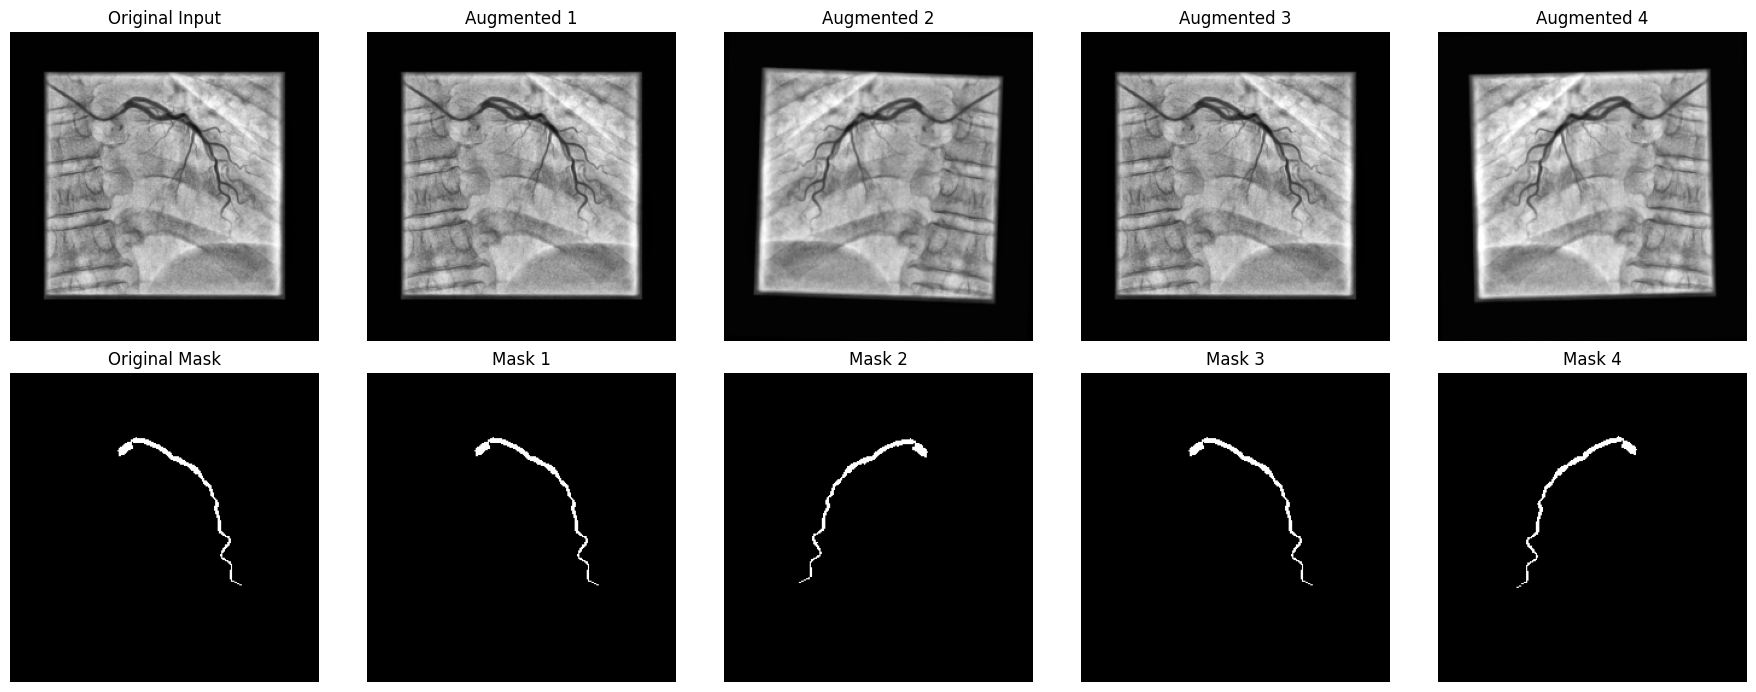

In [ ]:
fig, axes = plt.subplots(
    2, 5, figsize=(18, 7)
)

axes[0, 0].imshow(processed, cmap="gray")
axes[0, 0].set_title("Original Input")

axes[1, 0].imshow(binary_mask, cmap="gray")
axes[1, 0].set_title("Original Mask")

for i in range(1, 5):

    aug_img, aug_mask = augment_pair(
        processed.copy(),
        binary_mask.copy()
    )

    axes[0, i].imshow(aug_img, cmap="gray")
    axes[0, i].set_title(f"Augmented {i}")

    axes[1, i].imshow(aug_mask, cmap="gray")
    axes[1, i].set_title(f"Mask {i}")

for ax in axes.flat:
    ax.axis("off")

plt.tight_layout()

plt.savefig(
    M1 / "outputs/data_augmentation.png",
    dpi=200
)

plt.show()

###Correct Multi-class Label Mapping

In [ ]:
import json
import numpy as np

with open(DATA_DIR / "class_mapping.json") as f:

    CLASS_MAPPING = json.load(f)

def remap_multiclass_mask(mask, task):

    mapping = CLASS_MAPPING[task]

    result = np.full(
        mask.shape,
        -1,
        dtype=np.int32
    )

    for original, new in mapping.items():

        result[mask == int(original)] = new

    if np.any(result == -1):

        raise ValueError("Unknown annotation label")

    return result

print("Class mapping loaded successfully!")

Class mapping loaded successfully!


In [ ]:
QUICK_MODE = False

IMAGE_SIZE = 256

TRAIN_LIMIT = None
VAL_LIMIT = None
TEST_LIMIT = None

BATCH_SIZE = 8
EPOCHS = 50
LEARNING_RATE = 0.001

print("Full dataset training mode enabled!")

Full dataset training mode enabled!


###Save Preprocessed Dataset for Fast Training

In [ ]:
from tqdm.auto import tqdm
import json

limits = {
    "train": TRAIN_LIMIT,
    "val": VAL_LIMIT,
    "test": TEST_LIMIT
}

metadata = []

for task, ds in [
    ("syntax", artery_data),
    ("stenosis", stenosis_data)
]:

    for split in ["train", "val", "test"]:

        count = len(ds[split])

        limit = limits[split]

        if limit is not None:
            count = min(count, limit)

        rng = np.random.default_rng(SEED)

        indices = rng.permutation(
            len(ds[split])
        )[:count]

        images = []
        binary_masks = []
        multiclass_masks = []
        image_ids = []

        for idx in tqdm(
            indices,
            desc=f"Preprocessing {task}-{split}"
        ):

            sample = ds[split][int(idx)]

            image = preprocess_image(
                sample["image"], IMAGE_SIZE
            )

            binary = preprocess_mask(
                sample["mask"],
                IMAGE_SIZE,
                binary=True
            )

            multiclass = preprocess_mask(
                sample["mask"],
                IMAGE_SIZE,
                binary=False
            )

            multiclass = remap_multiclass_mask(
                multiclass, task
            )

            images.append(image)
            binary_masks.append(binary)
            multiclass_masks.append(multiclass)
            image_ids.append(sample["image_id"])

        path = PROCESSED_DIR / task / split

        path.mkdir(
            parents=True,
            exist_ok=True
        )

        np.save(
            path / "images.npy",
            np.array(images, dtype=np.float32)
        )

        np.save(
            path / "binary_masks.npy",
            np.array(binary_masks, dtype=np.uint8)
        )

        np.save(
            path / "multiclass_masks.npy",
            np.array(multiclass_masks, dtype=np.int32)
        )

        np.save(
            path / "image_ids.npy",
            np.array(image_ids)
        )

        metadata.append({
            "task": task,
            "split": split,
            "samples": count,
            "original_resolution": [512, 512],
            "processed_resolution": [
                IMAGE_SIZE, IMAGE_SIZE
            ],
            "pixel_spacing_mm": None,
            "seed": SEED
        })

        print(f"Saved: {path}")

with open(
    DATA_DIR / "dataset_metadata.json", "w"
) as f:

    json.dump(metadata, f, indent=4)

display(pd.DataFrame(metadata))

print("Preprocessing completed!")

Preprocessing syntax-train:   0%|          | 0/1000 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/ArteryAI/data/processed/syntax/train


Preprocessing syntax-val:   0%|          | 0/200 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/ArteryAI/data/processed/syntax/val


Preprocessing syntax-test:   0%|          | 0/300 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/ArteryAI/data/processed/syntax/test


... (4 outputs left out)

Preprocessing stenosis-test:   0%|          | 0/300 [00:00<?, ?it/s]

Saved: /content/drive/MyDrive/ArteryAI/data/processed/stenosis/test


,task,split,samples,original_resolution,processed_resolution,pixel_spacing_mm,seed
0,syntax,train,1000,"[512, 512]","[256, 256]",None,42
1,syntax,val,200,"[512, 512]","[256, 256]",None,42
2,syntax,test,300,"[512, 512]","[256, 256]",None,42
3,stenosis,train,1000,"[512, 512]","[256, 256]",None,42
4,stenosis,val,200,"[512, 512]","[256, 256]",None,42
5,stenosis,test,300,"[512, 512]","[256, 256]",None,42


Preprocessing completed!


###Permanently Update config.py

In [ ]:
%%writefile /content/drive/MyDrive/ArteryAI/src/config.py

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/ArteryAI")

DATA_DIR = ROOT / "data"
RAW_DIR = DATA_DIR / "raw"
PROCESSED_DIR = DATA_DIR / "processed"

MODEL_DIR = ROOT / "models/checkpoints"

M1 = ROOT / "Milestone-1"
M2 = ROOT / "Milestone-2"
M3 = ROOT / "Milestone-3"
M4 = ROOT / "Milestone-4"

SEED = 42

QUICK_MODE = False

IMAGE_SIZE = 256

TRAIN_LIMIT = None
VAL_LIMIT = None
TEST_LIMIT = None

BATCH_SIZE = 8
EPOCHS = 50
LEARNING_RATE = 0.001

DATASET_NAME = "ARCADE"
MODALITY = "X-ray Coronary Angiography"

Overwriting /content/drive/MyDrive/ArteryAI/src/config.py
